# DU-Net (Ye et al., 2022)

A densely connected U-Net trained with an L2 loss to map 100 m upward-continued data to the ground-level
field. Weights: `weights/dunet.pth`.

**Evaluation protocol (all notebooks).** The 10 synthetic test grids (32 × 32 nodes, 50 m spacing) are
scaled to [-1, 1] per grid. PSNR, SSIM, relative error (RE) and RMSE are computed on the central 24 × 24
window and reported as mean ± standard deviation (ddof = 0) over the 10 grids. Networks run in full FP32
with deterministic cuDNN (set when `gravdc` is imported, see `gravdc/precision.py`).

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # make the gravdc package importable

import numpy as np
import torch

from gravdc import evaluate, format_summary, load_model, load_test_set, save_result, summarize
from gravdc.plotting import show_reconstruction
from gravdc.table2 import compare

DATA_DIR = "../data/test"
RESULTS_DIR = "../results"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.9.0+cu128


## Data
Observation: the ground-level field continued 100 m upward in a single step (zero padding to 36 × 36).

In [2]:
from gravdc import upward_continue

names, x = load_test_set(DATA_DIR)
x = x.to(device)
y = upward_continue(x, 100)
print(len(names), "grids:", names)

10 grids: ['data11.mat', 'data111.mat', 'data211.mat', 'data311.mat', 'data411.mat', 'data511.mat', 'data611.mat', 'data711.mat', 'data811.mat', 'data911.mat']


## Model and inference

In [3]:
model = load_model("dunet", device)
with torch.no_grad():
    x_hat = model(y)

## Metrics

In [4]:
per_image = evaluate(x, x_hat)
compare("DU-Net", summarize(per_image))
save_result("DU-Net", per_image, names, RESULTS_DIR)

DU-Net
  metric             this run              Table 2
  PSNR       48.6022 ± 2.0723     48.6022 ± 2.0723  ✓
  SSIM        0.9984 ± 0.0007      0.9984 ± 0.0007  ✓
  RE          0.0113 ± 0.0018      0.0113 ± 0.0018  ✓
  RMSE        0.0075 ± 0.0019      0.0075 ± 0.0019  ✓


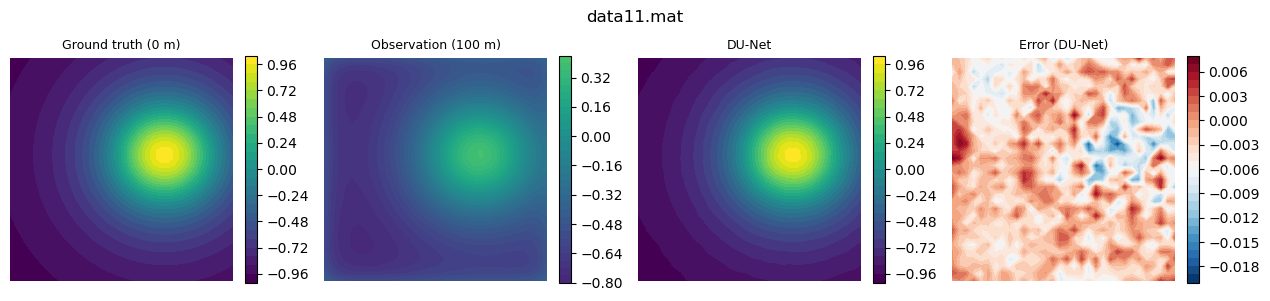

In [5]:
k = 0
show_reconstruction(x[k], y[k], {"DU-Net": x_hat[k]}, title=names[k])